In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


uber_df = pd.read_csv('uberdrive.csv')

uber_df.head()


,START_DATE*,END_DATE*,CATEGORY*,START*,STOP*,MILES*,PURPOSE*
0,01-01-2016 21:11,01-01-2016 21:17,Business,Fort Pierce,Fort Pierce,5.1,Meal/Entertain
1,01-02-2016 01:25,01-02-2016 01:37,Business,Fort Pierce,Fort Pierce,5.0,NaN
2,01-02-2016 20:25,01-02-2016 20:38,Business,Fort Pierce,Fort Pierce,4.8,Errand/Supplies
3,01-05-2016 17:31,01-05-2016 17:45,Business,Fort Pierce,Fort Pierce,4.7,Meeting
4,01-06-2016 14:42,01-06-2016 15:49,Business,Fort Pierce,West Palm Beach,63.7,Customer Visit


In [2]:
uber_df.tail()

,START_DATE*,END_DATE*,CATEGORY*,START*,STOP*,MILES*,PURPOSE*
1151,12/31/2016 13:24,12/31/2016 13:42,Business,Kar?chi,Unknown Location,3.9,Temporary Site
1152,12/31/2016 15:03,12/31/2016 15:38,Business,Unknown Location,Unknown Location,16.2,Meeting
1153,12/31/2016 21:32,12/31/2016 21:50,Business,Katunayake,Gampaha,6.4,Temporary Site
1154,12/31/2016 22:08,12/31/2016 23:51,Business,Gampaha,Ilukwatta,48.2,Temporary Site
1155,Totals,NaN,NaN,NaN,NaN,12204.7,NaN


In [3]:
uber_df.drop(uber_df.index[-1])

,START_DATE*,END_DATE*,CATEGORY*,START*,STOP*,MILES*,PURPOSE*
0,01-01-2016 21:11,01-01-2016 21:17,Business,Fort Pierce,Fort Pierce,5.1,Meal/Entertain
1,01-02-2016 01:25,01-02-2016 01:37,Business,Fort Pierce,Fort Pierce,5.0,NaN
2,01-02-2016 20:25,01-02-2016 20:38,Business,Fort Pierce,Fort Pierce,4.8,Errand/Supplies
3,01-05-2016 17:31,01-05-2016 17:45,Business,Fort Pierce,Fort Pierce,4.7,Meeting
4,01-06-2016 14:42,01-06-2016 15:49,Business,Fort Pierce,West Palm Beach,63.7,Customer Visit
...,...,...,...,...,...,...,...
1150,12/31/2016 1:07,12/31/2016 1:14,Business,Kar?chi,Kar?chi,0.7,Meeting
1151,12/31/2016 13:24,12/31/2016 13:42,Business,Kar?chi,Unknown Location,3.9,Temporary Site
1152,12/31/2016 15:03,12/31/2016 15:38,Business,Unknown Location,Unknown Location,16.2,Meeting
1153,12/31/2016 21:32,12/31/2016 21:50,Business,Katunayake,Gampaha,6.4,Temporary Site


In [4]:
uber_df.shape

(1156, 7)

In [5]:
uber_df.tail()

,START_DATE*,END_DATE*,CATEGORY*,START*,STOP*,MILES*,PURPOSE*
1151,12/31/2016 13:24,12/31/2016 13:42,Business,Kar?chi,Unknown Location,3.9,Temporary Site
1152,12/31/2016 15:03,12/31/2016 15:38,Business,Unknown Location,Unknown Location,16.2,Meeting
1153,12/31/2016 21:32,12/31/2016 21:50,Business,Katunayake,Gampaha,6.4,Temporary Site
1154,12/31/2016 22:08,12/31/2016 23:51,Business,Gampaha,Ilukwatta,48.2,Temporary Site
1155,Totals,NaN,NaN,NaN,NaN,12204.7,NaN


In [6]:
uber_df.size

8092

In [7]:
uber_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1156 entries, 0 to 1155
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   START_DATE*  1156 non-null   object 
 1   END_DATE*    1155 non-null   object 
 2   CATEGORY*    1155 non-null   object 
 3   START*       1155 non-null   object 
 4   STOP*        1155 non-null   object 
 5   MILES*       1156 non-null   float64
 6   PURPOSE*     653 non-null    object 
dtypes: float64(1), object(6)
memory usage: 63.3+ KB


In [8]:
import pandas as pd
import numpy as np
from datetime import datetime

uber_df = pd.read_csv('uberdrive.csv')

uber_df['START_DATE*'] = pd.to_datetime(uber_df['START_DATE*'], errors = 'coerce')

uber_df['END_DATE*'] = pd.to_datetime(uber_df['END_DATE*'], errors = 'coerce')


uber_df['date'] = pd.DatetimeIndex(uber_df['START_DATE*']).date

uber_df['time'] = pd.DatetimeIndex(uber_df['START_DATE*']).hour

uber_df['Day-Night'] = pd.cut( x = uber_df['time'], bins = [0,10,15,19,24], labels = ['Morning', 'Afternoon', 'Evening', 'Night'])

In [9]:
print(uber_df.head())

          START_DATE*           END_DATE* CATEGORY*       START*  \
0 2016-01-01 21:11:00 2016-01-01 21:17:00  Business  Fort Pierce   
1 2016-01-02 01:25:00 2016-01-02 01:37:00  Business  Fort Pierce   
2 2016-01-02 20:25:00 2016-01-02 20:38:00  Business  Fort Pierce   
3 2016-01-05 17:31:00 2016-01-05 17:45:00  Business  Fort Pierce   
4 2016-01-06 14:42:00 2016-01-06 15:49:00  Business  Fort Pierce   

             STOP*  MILES*         PURPOSE*        date  time  Day-Night  
0      Fort Pierce     5.1   Meal/Entertain  2016-01-01  21.0      Night  
1      Fort Pierce     5.0              NaN  2016-01-02   1.0    Morning  
2      Fort Pierce     4.8  Errand/Supplies  2016-01-02  20.0      Night  
3      Fort Pierce     4.7          Meeting  2016-01-05  17.0    Evening  
4  West Palm Beach    63.7   Customer Visit  2016-01-06  14.0  Afternoon  


In [10]:
print(uber_df.tail())

     START_DATE* END_DATE* CATEGORY*            START*             STOP*  \
1151         NaT       NaT  Business           Kar?chi  Unknown Location   
1152         NaT       NaT  Business  Unknown Location  Unknown Location   
1153         NaT       NaT  Business        Katunayake           Gampaha   
1154         NaT       NaT  Business           Gampaha         Ilukwatta   
1155         NaT       NaT       NaN               NaN               NaN   

       MILES*        PURPOSE* date  time Day-Night  
1151      3.9  Temporary Site  NaT   NaN       NaN  
1152     16.2         Meeting  NaT   NaN       NaN  
1153      6.4  Temporary Site  NaT   NaN       NaN  
1154     48.2  Temporary Site  NaT   NaN       NaN  
1155  12204.7             NaN  NaT   NaN       NaN  


In [11]:
print(uber_df['START_DATE*'].isna().sum())

735


In [20]:
import pandas as pd

uber_df = pd.read_csv('uberdrive.csv')

# Convert mixed date formats
uber_df['START_DATE*'] = pd.to_datetime(
    uber_df['START_DATE*'],
    format='mixed',
    errors='coerce'
)

uber_df['END_DATE*'] = pd.to_datetime(
    uber_df['END_DATE*'],
    format='mixed',
    errors='coerce'
)

# Remove the Totals row
uber_df = uber_df.dropna(subset=['START_DATE*'])

# Create new columns
uber_df['date'] = uber_df['START_DATE*'].dt.date
uber_df['time'] = uber_df['START_DATE*'].dt.hour

uber_df['Day-Night'] = pd.cut(
    uber_df['time'],
    bins=[0, 10, 15, 19, 24],
    labels=['Morning', 'Afternoon', 'Evening', 'Night'],
    include_lowest=True
)

print(uber_df.tail())

             START_DATE*           END_DATE* CATEGORY*            START*  \
1150 2016-12-31 01:07:00 2016-12-31 01:14:00  Business           Kar?chi   
1151 2016-12-31 13:24:00 2016-12-31 13:42:00  Business           Kar?chi   
1152 2016-12-31 15:03:00 2016-12-31 15:38:00  Business  Unknown Location   
1153 2016-12-31 21:32:00 2016-12-31 21:50:00  Business        Katunayake   
1154 2016-12-31 22:08:00 2016-12-31 23:51:00  Business           Gampaha   

                 STOP*  MILES*        PURPOSE*        date  time  Day-Night  
1150           Kar?chi     0.7         Meeting  2016-12-31     1    Morning  
1151  Unknown Location     3.9  Temporary Site  2016-12-31    13  Afternoon  
1152  Unknown Location    16.2         Meeting  2016-12-31    15  Afternoon  
1153           Gampaha     6.4  Temporary Site  2016-12-31    21      Night  
1154         Ilukwatta    48.2  Temporary Site  2016-12-31    22      Night  


<h1> data vizualization </h1>

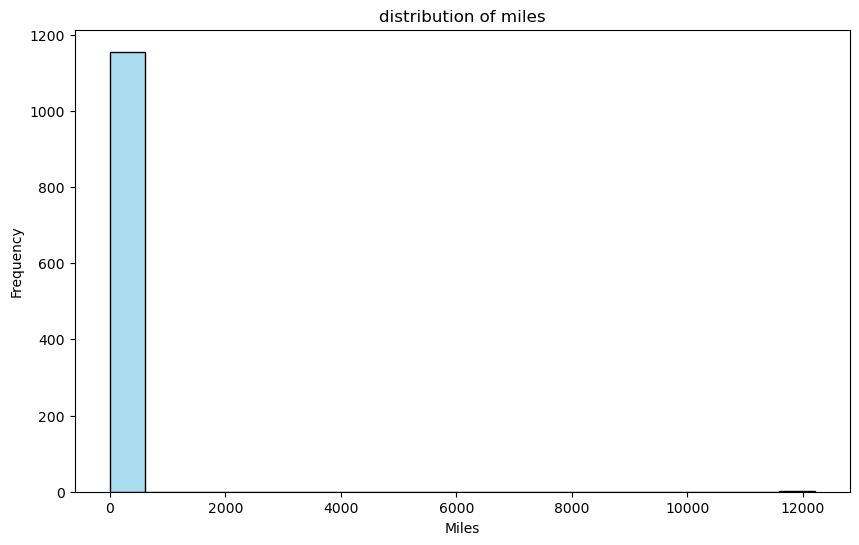

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

uber_df = pd.read_csv('uberdrive.csv')

plt.figure(figsize=(10,6))
sns.histplot(uber_df['MILES*'],bins = 20, color = 'Skyblue', edgecolor = 'Black', alpha = 0.7)
plt.xlabel('Miles')
plt.ylabel('Frequency')
plt.title('distribution of miles')
plt.show()

In [14]:
print(uber_df['START*'].nunique())

177


In [15]:
pd.value_counts(uber_df['START*']).iloc[:10].index

C:\Users\abdul jabbar\AppData\Local\Temp\ipykernel_16492\2076397004.py:1: FutureWarning: pandas.value_counts is deprecated and will be removed in a future version. Use pd.Series(obj).value_counts() instead.
  pd.value_counts(uber_df['START*']).iloc[:10].index


Index(['Cary', 'Unknown Location', 'Morrisville', 'Whitebridge', 'Islamabad',
       'Durham', 'Lahore', 'Raleigh', 'Kar?chi', 'Westpark Place'],
      dtype='object', name='START*')

C:\Users\abdul jabbar\AppData\Local\Temp\ipykernel_16492\1471382963.py:2: FutureWarning: pandas.value_counts is deprecated and will be removed in a future version. Use pd.Series(obj).value_counts() instead.
  sns.countplot(y = 'START*', order = pd.value_counts(uber_df['START*']).iloc[:10].index, data = uber_df, palette ='viridis',edgecolor ='black')
C:\Users\abdul jabbar\AppData\Local\Temp\ipykernel_16492\1471382963.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y = 'START*', order = pd.value_counts(uber_df['START*']).iloc[:10].index, data = uber_df, palette ='viridis',edgecolor ='black')


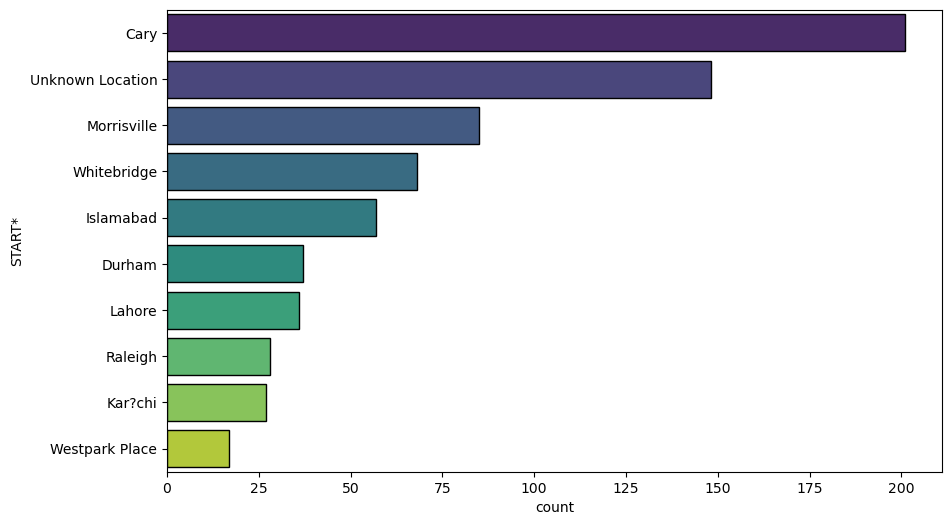

In [16]:
plt.figure(figsize = (10,6))
sns.countplot(y = 'START*', order = pd.value_counts(uber_df['START*']).iloc[:10].index, data = uber_df, palette ='viridis',edgecolor ='black')
plt.show()

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

obj = (uber_df.dtypes == 'object')
object_col = list(obj[obj].index)
unique_values = {}

for col in object_col:
    unique_values[col] = uber_df[col].unique().size

unique_values

{'START_DATE*': 1155,
 'END_DATE*': 1155,
 'CATEGORY*': 3,
 'START*': 178,
 'STOP*': 189,
 'PURPOSE*': 11}

C:\Users\abdul jabbar\AppData\Local\Temp\ipykernel_16492\638364797.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(uber_df['CATEGORY*'], palette = 'Set2')
C:\Users\abdul jabbar\AppData\Local\Temp\ipykernel_16492\638364797.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(uber_df['PURPOSE*'], palette = 'Set2')


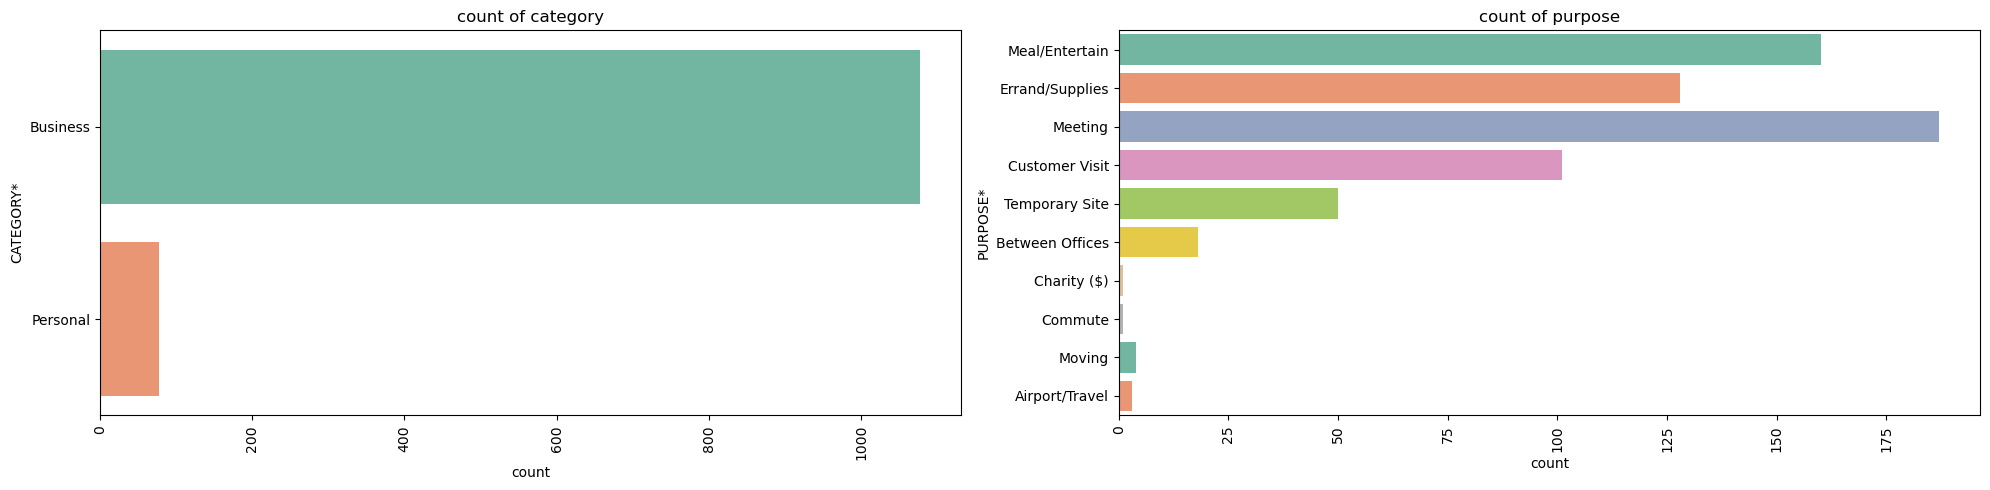

In [18]:
uber_df = pd.read_csv('uberdrive.csv')
plt.figure(figsize = (20,5))
plt.subplot(1,2,1)
sns.countplot(uber_df['CATEGORY*'], palette = 'Set2')
plt.xticks(rotation = 90)
plt.title('count of category')

plt.subplot(1,2,2)
sns.countplot(uber_df['PURPOSE*'], palette = 'Set2')
plt.xticks(rotation = 90)
plt.title('count of purpose')
plt.tight_layout()
plt.show()


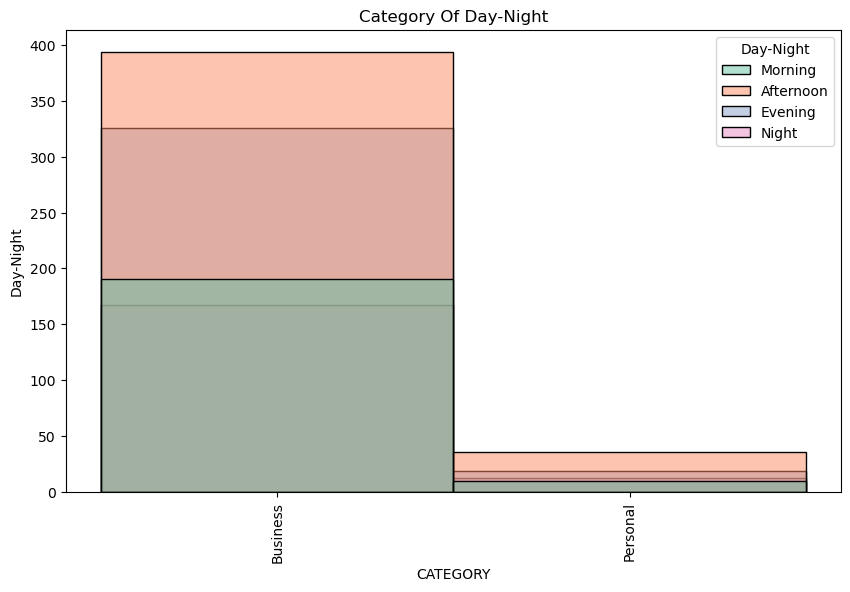

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize = (10,6))
sns.histplot(data = uber_df, x = 'CATEGORY*', hue = 'Day-Night', palette = 'Set2')
plt.xticks(rotation = 90)
plt.xlabel('CATEGORY')
plt.ylabel('Day-Night')
plt.title('Category Of Day-Night')

plt.show()

In [ ]:
print(uber_df.columns)

In [ ]:
print(uber_df.tail())

In [ ]:
print(uber_df.head())

In [22]:
import pandas as pd

uber_df = pd.read_csv('uberdrive.csv')

# Convert mixed date formats
uber_df['START_DATE*'] = pd.to_datetime(
    uber_df['START_DATE*'],
    format='mixed',
    errors='coerce'
)

uber_df['END_DATE*'] = pd.to_datetime(
    uber_df['END_DATE*'],
    format='mixed',
    errors='coerce'
)

# Remove the Totals row
uber_df = uber_df.dropna(subset=['START_DATE*'])

# Create new columns
uber_df['date'] = uber_df['START_DATE*'].dt.date
uber_df['time'] = uber_df['START_DATE*'].dt.hour

uber_df['Day-Night'] = pd.cut(
    uber_df['time'],
    bins=[0, 10, 15, 19, 24],
    labels=['Morning', 'Afternoon', 'Evening', 'Night'],
    include_lowest=True
)

print(uber_df.tail())

             START_DATE*           END_DATE* CATEGORY*            START*  \
1150 2016-12-31 01:07:00 2016-12-31 01:14:00  Business           Kar?chi   
1151 2016-12-31 13:24:00 2016-12-31 13:42:00  Business           Kar?chi   
1152 2016-12-31 15:03:00 2016-12-31 15:38:00  Business  Unknown Location   
1153 2016-12-31 21:32:00 2016-12-31 21:50:00  Business        Katunayake   
1154 2016-12-31 22:08:00 2016-12-31 23:51:00  Business           Gampaha   

                 STOP*  MILES*        PURPOSE*        date  time  Day-Night  
1150           Kar?chi     0.7         Meeting  2016-12-31     1    Morning  
1151  Unknown Location     3.9  Temporary Site  2016-12-31    13  Afternoon  
1152  Unknown Location    16.2         Meeting  2016-12-31    15  Afternoon  
1153           Gampaha     6.4  Temporary Site  2016-12-31    21      Night  
1154         Ilukwatta    48.2  Temporary Site  2016-12-31    22      Night  


In [23]:
import pandas as pd

uber_df = pd.read_csv('uberdrive.csv')

uber_df['START_DATE*'] = pd.to_datetime(
    uber_df['START_DATE*'],
    format='mixed',
    errors='coerce'
)

uber_df['time'] = uber_df['START_DATE*'].dt.hour

uber_df['Day-Night'] = pd.cut(
    uber_df['time'],
    bins=[0,10,15,19,24],
    labels=['Morning','Afternoon','Evening','Night'],
    include_lowest=True
)

print(uber_df[['time','Day-Night']].head())

   time  Day-Night
0  21.0      Night
1   1.0    Morning
2  20.0      Night
3  17.0    Evening
4  14.0  Afternoon


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



plt.figure(figsize = (10,6))
heatmap_data = uber_df.groupby(['PURPOSE*','Day-Night']).size().unstack()
sns.heatmap(heatmap_data, annot = True, cmap = 'YlGnBu', fmt = 'd')
plt.title('heatmap of purpose vs day-night')
plt.xlabel('Category')
plt.ylabel('Day-Night')
plt.show()

C:\Users\abdul jabbar\AppData\Local\Temp\ipykernel_16492\712292652.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  heatmap_data = uber_df.groupby(


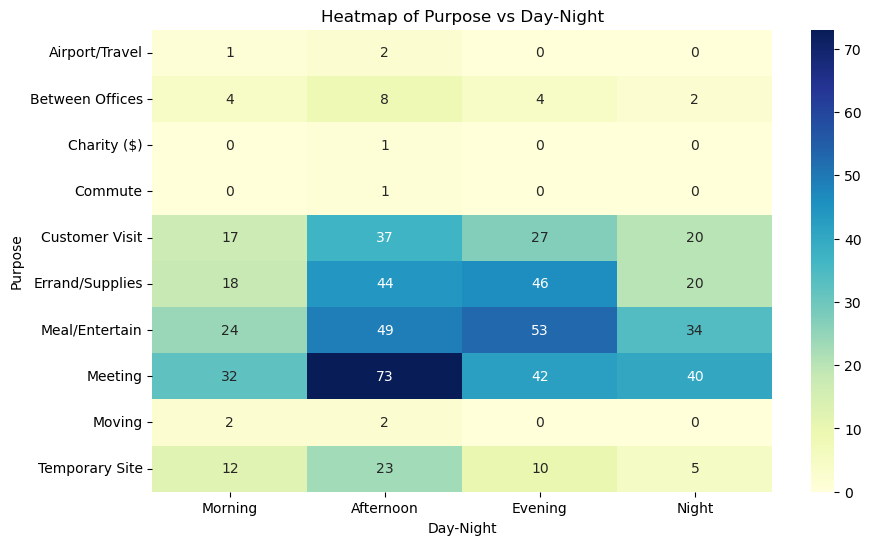

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


plt.figure(figsize=(10,6))

heatmap_data = uber_df.groupby(
    ['PURPOSE*', 'Day-Night']
).size().unstack()

sns.heatmap(
    heatmap_data,
    annot=True,
    cmap='YlGnBu',
    fmt='d'
)

plt.title('Heatmap of Purpose vs Day-Night')
plt.xlabel('Day-Night')
plt.ylabel('Purpose')

plt.show()

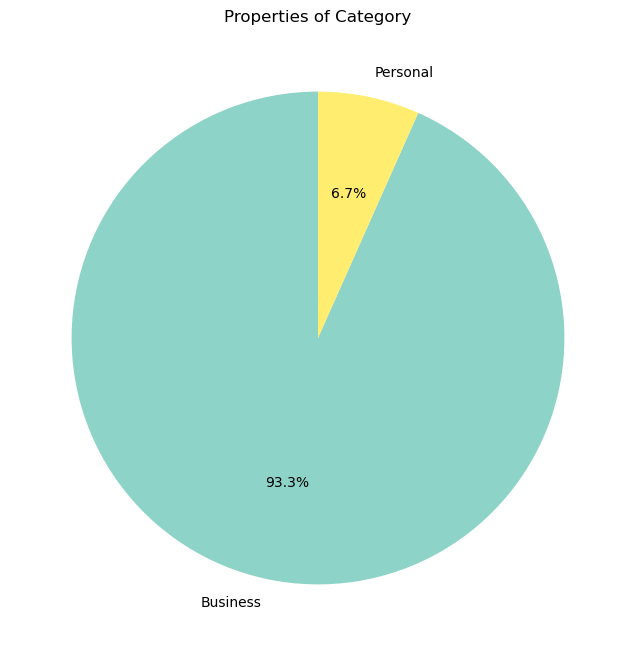

In [25]:
plt.figure(figsize = (8,8))
uber_df['CATEGORY*'].value_counts().plot.pie(autopct = '%1.1f%%', startangle = 90, cmap = 'Set3')
plt.title('Properties of Category')
plt.ylabel('')
plt.show()

In [ ]:
uber_df['PURPOSE*']

In [ ]:
print(uber_df.head())

In [ ]:
print(uber_df.tail())

In [ ]:
print(uber_df.tail())

C:\Users\abdul jabbar\AppData\Local\Temp\ipykernel_16492\3806053413.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  heatmap_data = uber_df.groupby(['PURPOSE*','Day-Night']).size().unstack()


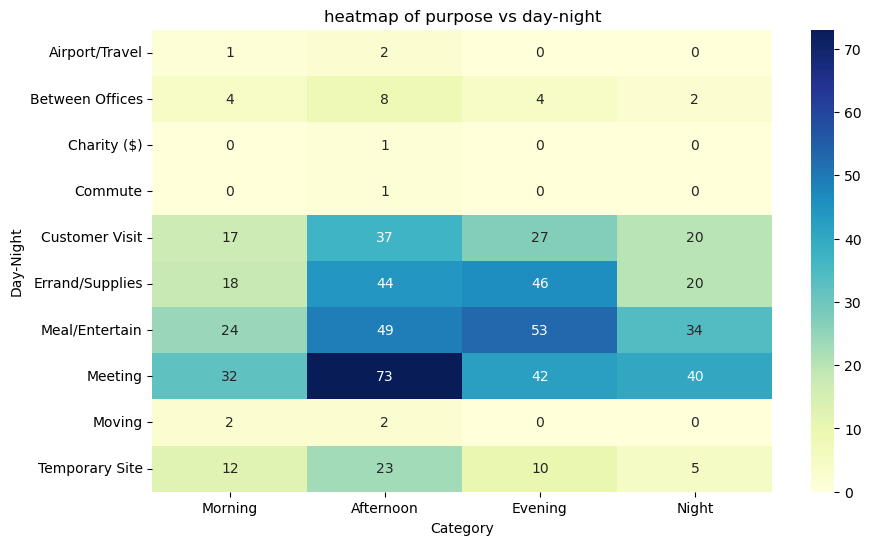

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


plt.figure(figsize = (10,6))
heatmap_data = uber_df.groupby(['PURPOSE*','Day-Night']).size().unstack()
sns.heatmap(heatmap_data, annot = True, cmap = 'YlGnBu', fmt = 'd')
plt.title('heatmap of purpose vs day-night')
plt.xlabel('Category')
plt.ylabel('Day-Night')
plt.show()

In [ ]:
print(uber_df.columns)

In [ ]:
print(uber_df.columns.tolist())

In [ ]:
print(uber_df.columns)

In [ ]:
print(uber_df.tail())

C:\Users\abdul jabbar\AppData\Local\Temp\ipykernel_16492\927877807.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  heatmap_data = uber_df.groupby(


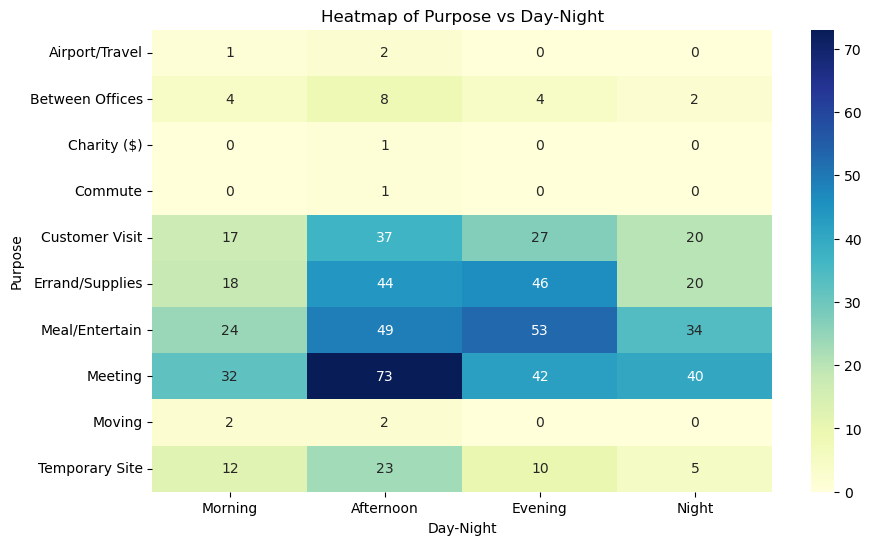

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,6))

heatmap_data = uber_df.groupby(
    ['PURPOSE*', 'Day-Night']
).size().unstack()

sns.heatmap(
    heatmap_data,
    annot=True,
    cmap='YlGnBu',
    fmt='d'
)

plt.title('Heatmap of Purpose vs Day-Night')
plt.xlabel('Day-Night')
plt.ylabel('Purpose')

plt.show()

C:\Users\abdul jabbar\AppData\Local\Temp\ipykernel_16492\3806053413.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  heatmap_data = uber_df.groupby(['PURPOSE*','Day-Night']).size().unstack()


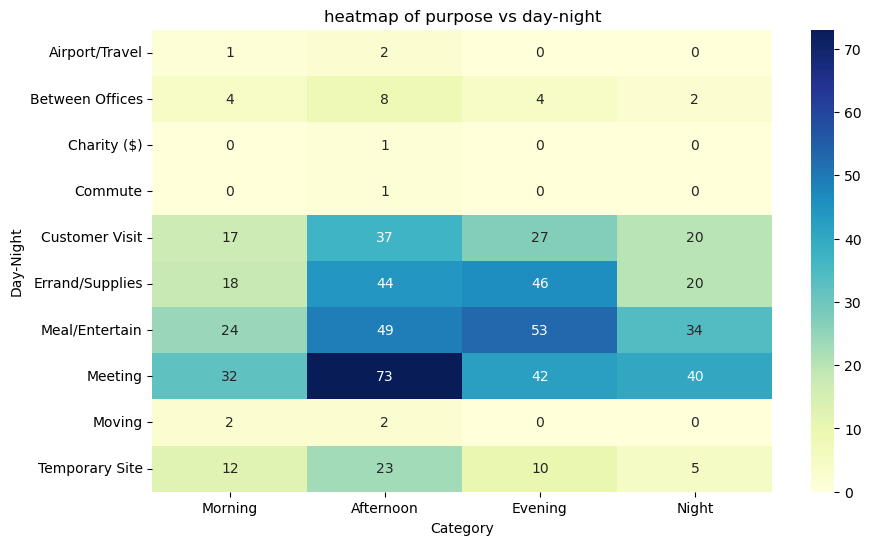

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


plt.figure(figsize = (10,6))
heatmap_data = uber_df.groupby(['PURPOSE*','Day-Night']).size().unstack()
sns.heatmap(heatmap_data, annot = True, cmap = 'YlGnBu', fmt = 'd')
plt.title('heatmap of purpose vs day-night')
plt.xlabel('Category')
plt.ylabel('Day-Night')
plt.show()

C:\Users\abdul jabbar\AppData\Local\Temp\ipykernel_16492\2399430101.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data = uber_df, x = 'Day-Night', y = 'MILES*', palette = 'coolwarm')


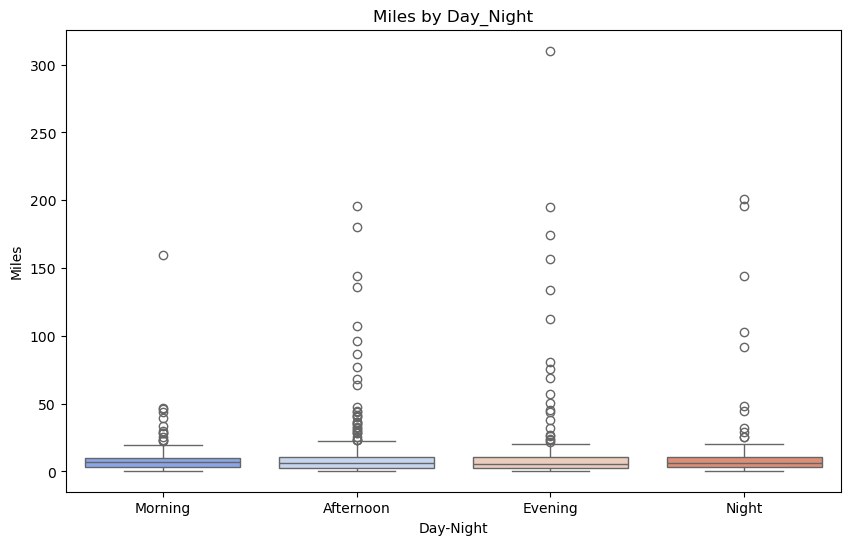

In [29]:
plt.figure(figsize = (10,6))
sns.boxplot(data = uber_df, x = 'Day-Night', y = 'MILES*', palette = 'coolwarm')
plt.title('Miles by Day_Night')
plt.xlabel('Day-Night')
plt.ylabel('Miles')
plt.show()

C:\Users\abdul jabbar\anaconda3\Lib\site-packages\seaborn\axisgrid.py:718: UserWarning: Using the boxplot function without specifying `order` is likely to produce an incorrect plot.
  warnings.warn(warning)
C:\Users\abdul jabbar\anaconda3\Lib\site-packages\seaborn\axisgrid.py:854: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  func(*plot_args, **plot_kwargs)
C:\Users\abdul jabbar\anaconda3\Lib\site-packages\seaborn\axisgrid.py:854: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  func(*plot_args, **plot_kwargs)


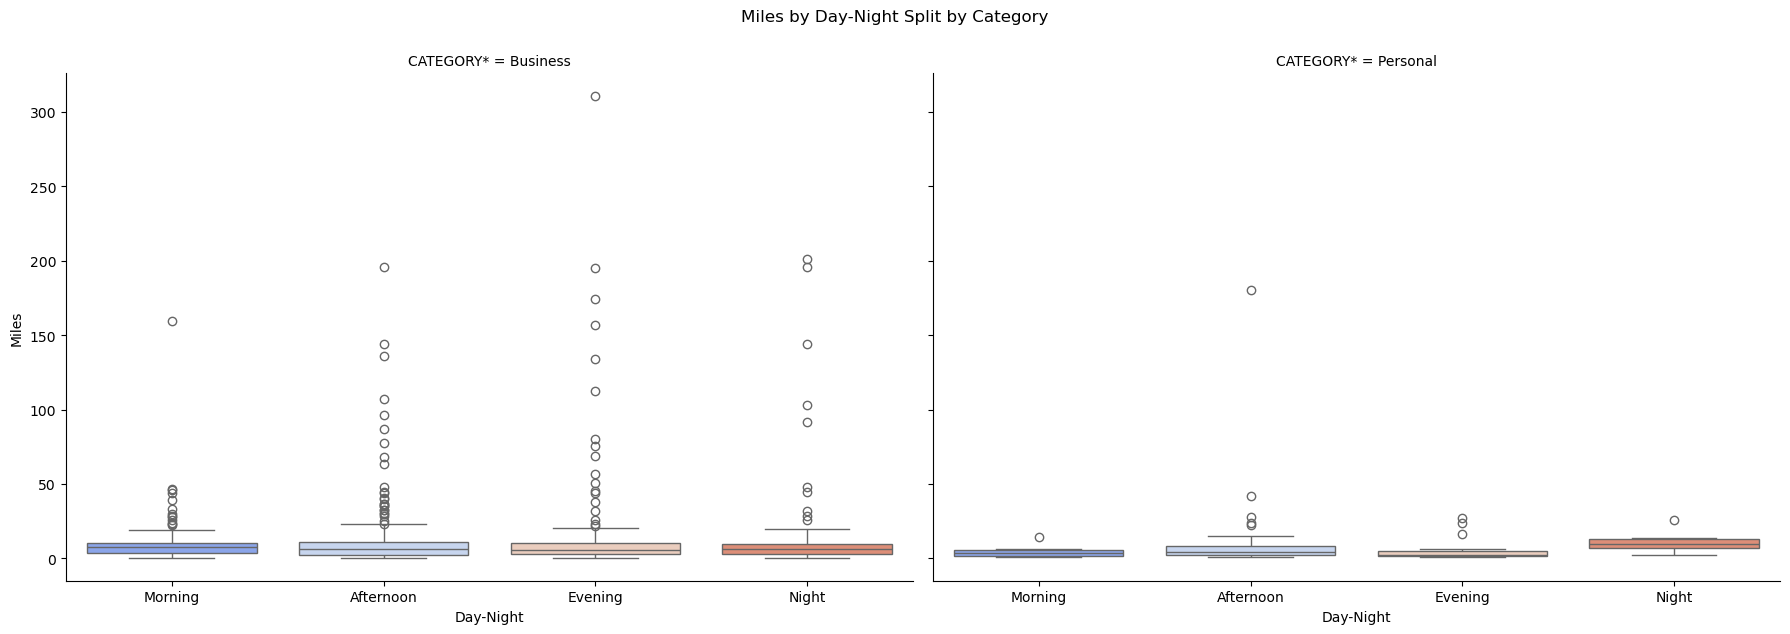

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

g = sns.FacetGrid(uber_df, col = 'CATEGORY*', height = 6, aspect = 1.5)

g.map(sns.boxplot, 'Day-Night', 'MILES*', palette = 'coolwarm')

g.set_axis_labels('Day-Night', 'Miles')

g.fig.suptitle('Miles by Day-Night Split by Category', y = 1.05)



plt.show()

C:\Users\abdul jabbar\AppData\Local\Temp\ipykernel_16492\3652447671.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot( data = uber_df , x = 'Day-Night' , y = 'MILES*', palette = 'Blues')


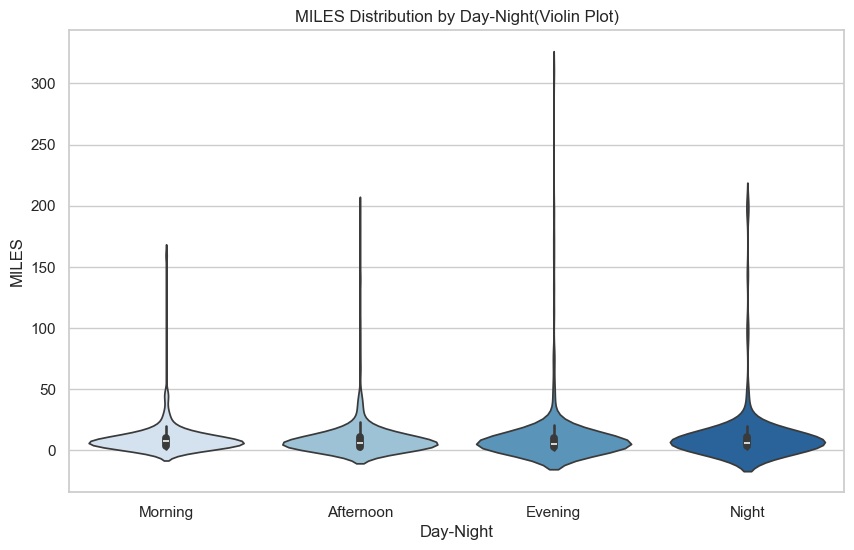

In [31]:
sns.set(style = 'whitegrid')
plt.figure(figsize = (10,6))
sns.violinplot( data = uber_df , x = 'Day-Night' , y = 'MILES*', palette = 'Blues')
plt.title('MILES Distribution by Day-Night(Violin Plot)')
plt.xlabel('Day-Night')
plt.ylabel('MILES')
plt.show()

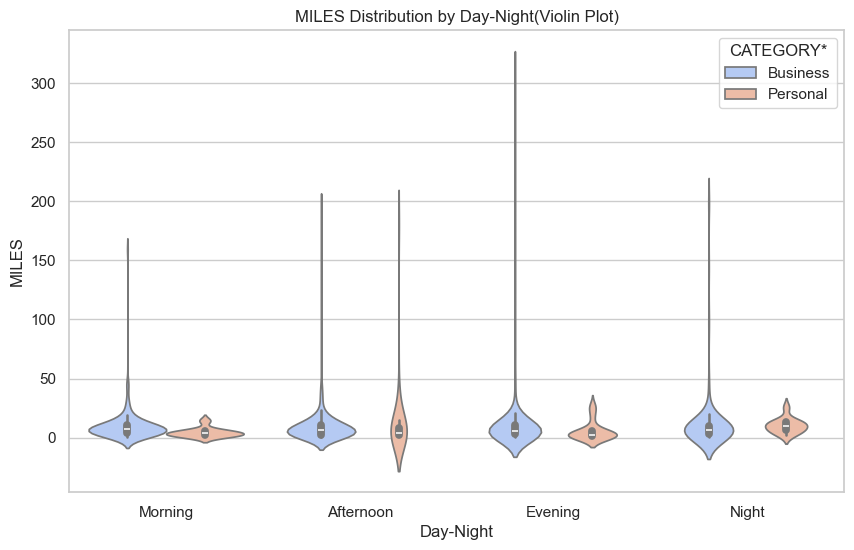

In [32]:
sns.set(style = 'whitegrid')
plt.figure(figsize = (10,6))
sns.violinplot( data = uber_df , x = 'Day-Night' , y = 'MILES*', hue = 'CATEGORY*', palette = 'coolwarm')
plt.title('MILES Distribution by Day-Night(Violin Plot)')
plt.xlabel('Day-Night')
plt.ylabel('MILES')
plt.show()

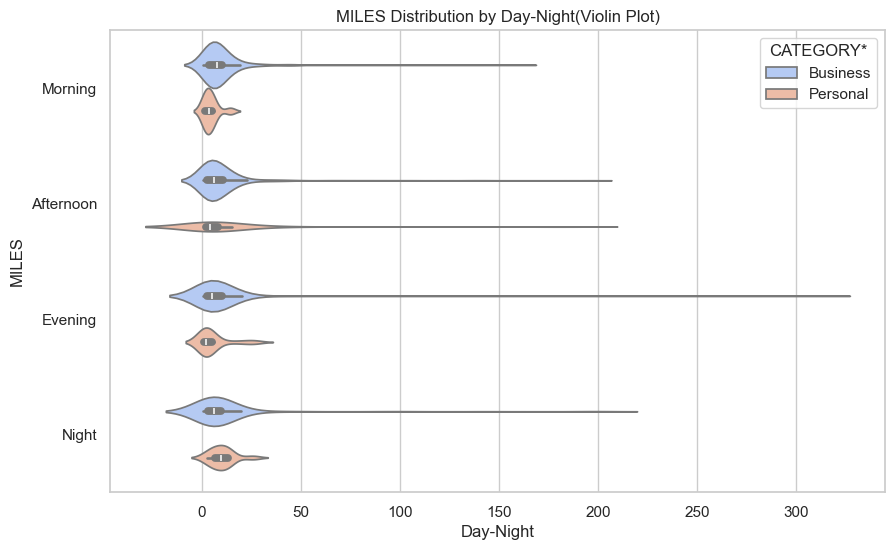

In [33]:
sns.set(style = 'whitegrid')
plt.figure(figsize = (10,6))
sns.violinplot( data = uber_df , y = 'Day-Night' , x = 'MILES*', hue = 'CATEGORY*', palette = 'coolwarm')
plt.title('MILES Distribution by Day-Night(Violin Plot)')
plt.xlabel('Day-Night')
plt.ylabel('MILES')
plt.show()

C:\Users\abdul jabbar\AppData\Local\Temp\ipykernel_16492\2721461935.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot( data = uber_df , x = 'Day-Night' , y = 'MILES*', inner = 'box', palette = 'coolwarm')


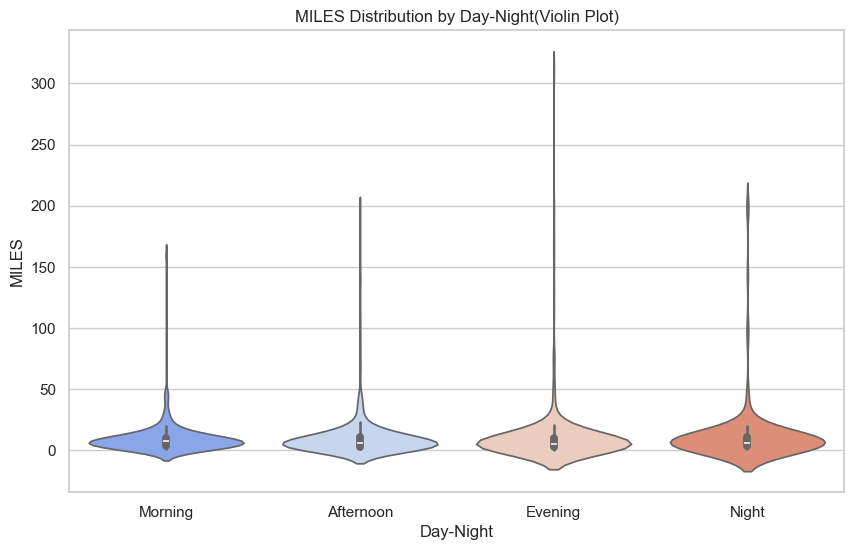

In [34]:
sns.set(style = 'whitegrid')
plt.figure(figsize = (10,6))
sns.violinplot( data = uber_df , x = 'Day-Night' , y = 'MILES*', inner = 'box', palette = 'coolwarm')
plt.title('MILES Distribution by Day-Night(Violin Plot)')
plt.xlabel('Day-Night')
plt.ylabel('MILES')
plt.show()

C:\Users\abdul jabbar\AppData\Local\Temp\ipykernel_16492\207744125.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot( data = uber_df , y = 'Day-Night' , x = 'MILES*', scale = 'width', palette = 'coolwarm')
C:\Users\abdul jabbar\AppData\Local\Temp\ipykernel_16492\207744125.py:3: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot( data = uber_df , y = 'Day-Night' , x = 'MILES*', scale = 'width', palette = 'coolwarm')


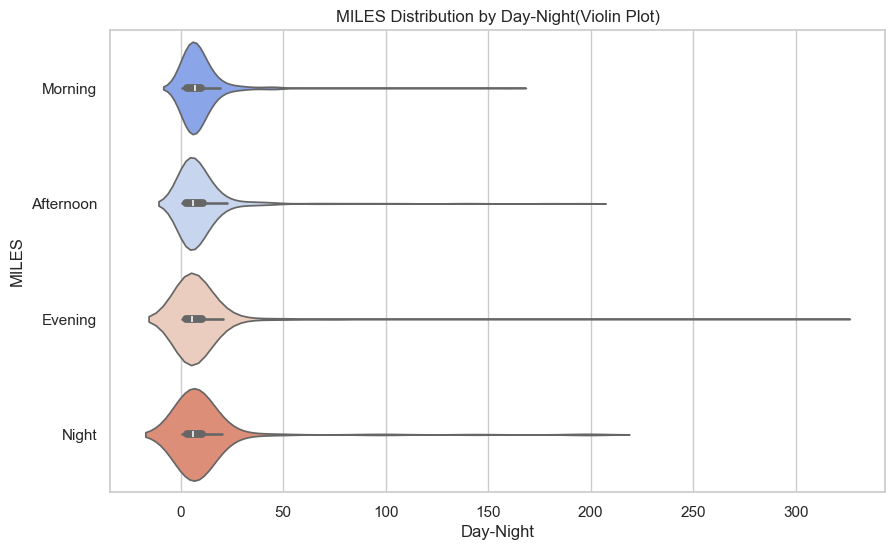

In [35]:
sns.set(style = 'whitegrid')
plt.figure(figsize = (10,6))
sns.violinplot( data = uber_df , y = 'Day-Night' , x = 'MILES*', scale = 'width', palette = 'coolwarm')
plt.title('MILES Distribution by Day-Night(Violin Plot)')
plt.xlabel('Day-Night')
plt.ylabel('MILES')
plt.show()

C:\Users\abdul jabbar\AppData\Local\Temp\ipykernel_16492\1233366348.py:2: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data = uber_df , x = 'PURPOSE*' , y = 'MILES*' , estimator = sum , ci= None , palette = 'Set1')
C:\Users\abdul jabbar\AppData\Local\Temp\ipykernel_16492\1233366348.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data = uber_df , x = 'PURPOSE*' , y = 'MILES*' , estimator = sum , ci= None , palette = 'Set1')


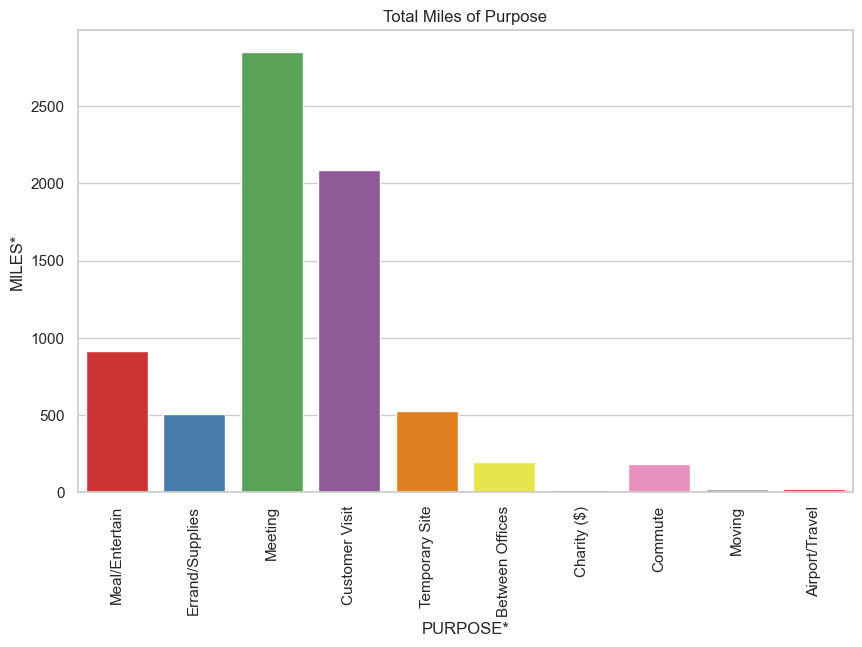

In [36]:
plt.figure(figsize =(10,6))
sns.barplot(data = uber_df , x = 'PURPOSE*' , y = 'MILES*' , estimator = sum , ci= None , palette = 'Set1')
plt.xticks(rotation = 90)
plt.title('Total Miles of Purpose')
plt.show()

C:\Users\abdul jabbar\AppData\Local\Temp\ipykernel_16492\1628440087.py:2: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data = uber_df , x = 'PURPOSE*' , y = 'MILES*' , estimator = np.mean , ci= None , palette = 'Set1')
C:\Users\abdul jabbar\AppData\Local\Temp\ipykernel_16492\1628440087.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data = uber_df , x = 'PURPOSE*' , y = 'MILES*' , estimator = np.mean , ci= None , palette = 'Set1')


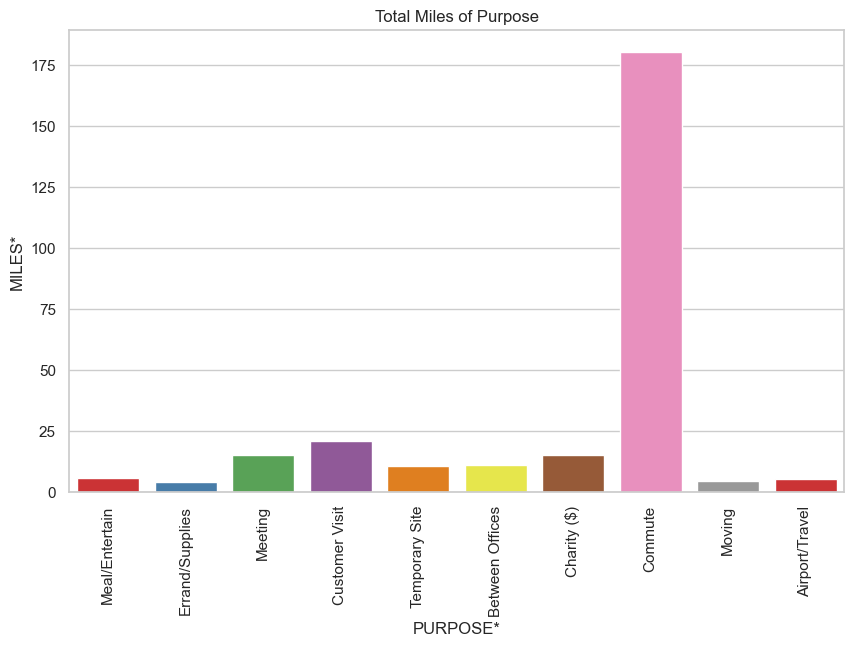

In [37]:
plt.figure(figsize =(10,6))
sns.barplot(data = uber_df , x = 'PURPOSE*' , y = 'MILES*' , estimator = np.mean , ci= None , palette = 'Set1')
plt.xticks(rotation = 90)
plt.title('Total Miles of Purpose')
plt.show()

C:\Users\abdul jabbar\AppData\Local\Temp\ipykernel_16492\3311665485.py:2: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data = uber_df , x = 'PURPOSE*' , y = 'MILES*' , estimator = np.median , ci= None , palette = 'Set1')
C:\Users\abdul jabbar\AppData\Local\Temp\ipykernel_16492\3311665485.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data = uber_df , x = 'PURPOSE*' , y = 'MILES*' , estimator = np.median , ci= None , palette = 'Set1')


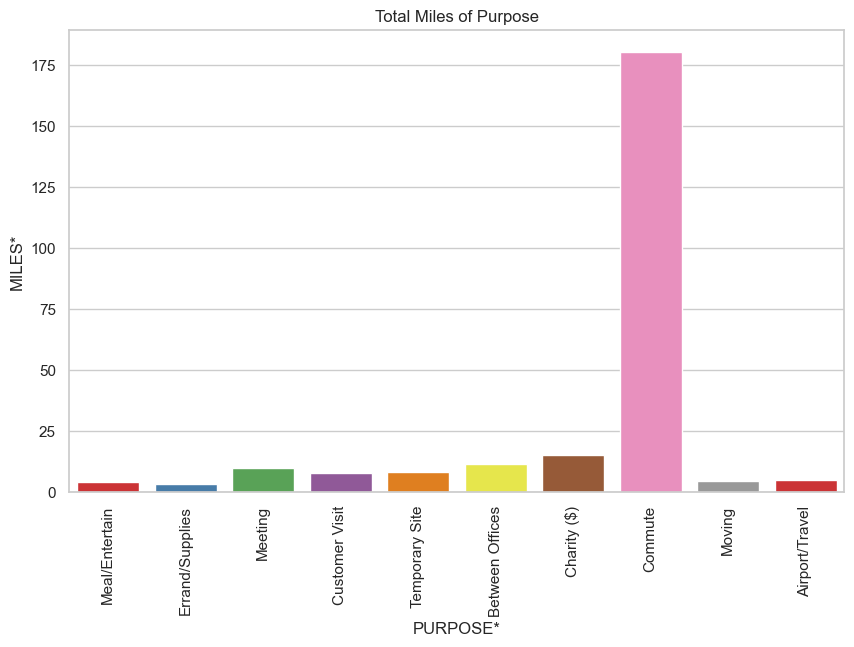

In [38]:
plt.figure(figsize =(10,6))
sns.barplot(data = uber_df , x = 'PURPOSE*' , y = 'MILES*' , estimator = np.median , ci= None , palette = 'Set1')
plt.xticks(rotation = 90)
plt.title('Total Miles of Purpose')
plt.show()

C:\Users\abdul jabbar\AppData\Local\Temp\ipykernel_16492\2910344660.py:2: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 68)` for the same effect.

  sns.barplot(data = uber_df , x = 'PURPOSE*' , y = 'MILES*' , estimator = sum , ci= 68 , palette = 'coolwarm')
C:\Users\abdul jabbar\AppData\Local\Temp\ipykernel_16492\2910344660.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data = uber_df , x = 'PURPOSE*' , y = 'MILES*' , estimator = sum , ci= 68 , palette = 'coolwarm')


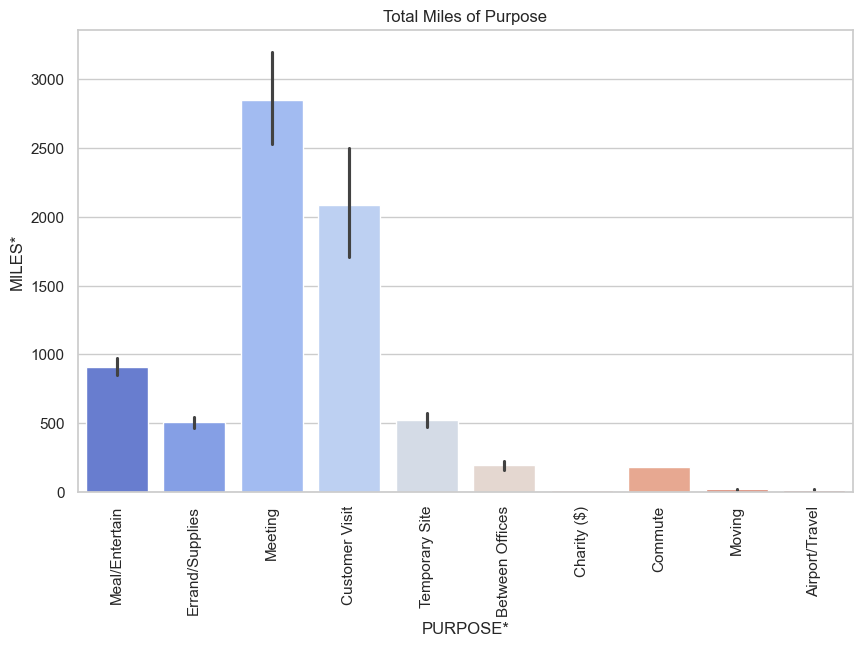

In [39]:
plt.figure(figsize =(10,6))
sns.barplot(data = uber_df , x = 'PURPOSE*' , y = 'MILES*' , estimator = sum , ci= 68 , palette = 'coolwarm')
plt.xticks(rotation = 90)
plt.title('Total Miles of Purpose')
plt.show()

C:\Users\abdul jabbar\AppData\Local\Temp\ipykernel_16492\2756520005.py:4: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 68)` for the same effect.

  sns.barplot(data = uber_df , x = 'PURPOSE*' , y = 'MILES*' ,hue = 'Day-Night', estimator = sum , ci= 68 , palette = 'Set2')


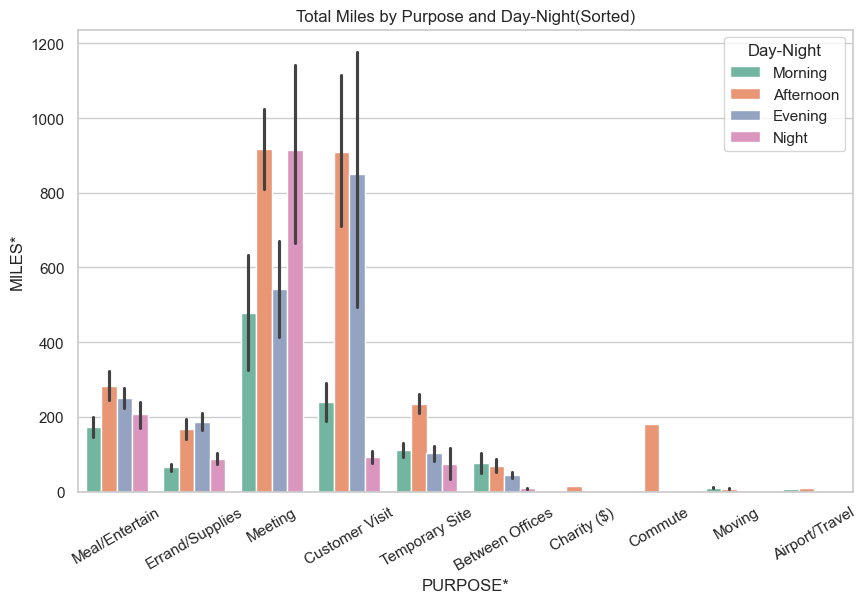

In [40]:
plt.figure(figsize =(10,6))

order = uber_df.groupby('PURPOSE*')['MILES*'].sum().sort_values(ascending = False).index
sns.barplot(data = uber_df , x = 'PURPOSE*' , y = 'MILES*' ,hue = 'Day-Night', estimator = sum , ci= 68 , palette = 'Set2')
plt.xticks(rotation = 30)
plt.title('Total Miles by Purpose and Day-Night(Sorted)')
plt.show()

C:\Users\abdul jabbar\AppData\Local\Temp\ipykernel_16492\295603569.py:3: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 68)` for the same effect.

  sns.barplot(data = uber_df , x = 'PURPOSE*' , y = 'MILES*' ,hue = 'Day-Night', estimator = sum , ci= 68 , palette = 'Set2')


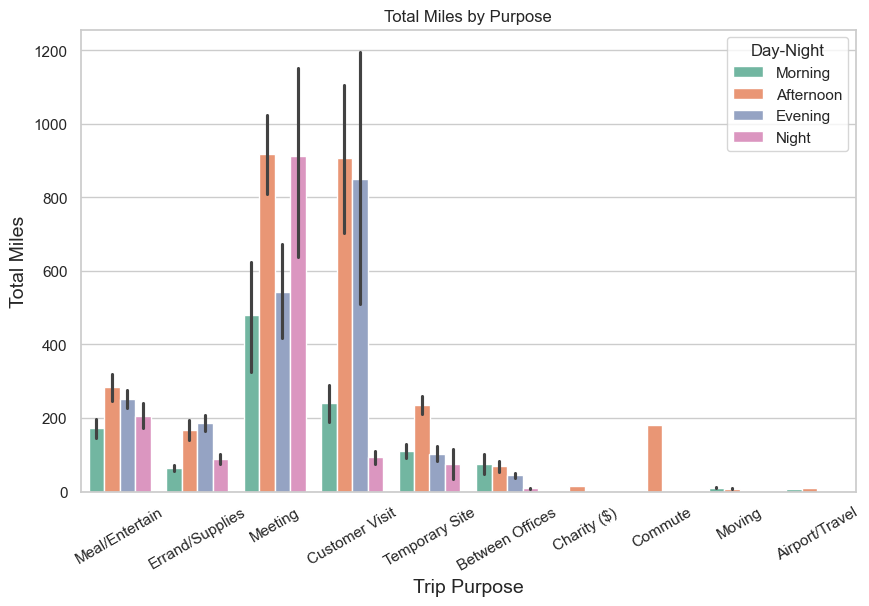

In [41]:
plt.figure(figsize =(10,6))

sns.barplot(data = uber_df , x = 'PURPOSE*' , y = 'MILES*' ,hue = 'Day-Night', estimator = sum , ci= 68 , palette = 'Set2')
plt.xticks(rotation = 30)
plt.xlabel('Trip Purpose',fontsize = 14)
plt.ylabel('Total Miles',fontsize = 14)
plt.title('Total Miles by Purpose')
plt.show()

C:\Users\abdul jabbar\AppData\Local\Temp\ipykernel_16492\2811716967.py:3: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 68)` for the same effect.

  ax = sns.barplot(data = uber_df , x = 'PURPOSE*' , y = 'MILES*' ,hue = 'Day-Night', estimator = sum , ci= 68 , palette = 'Set2')


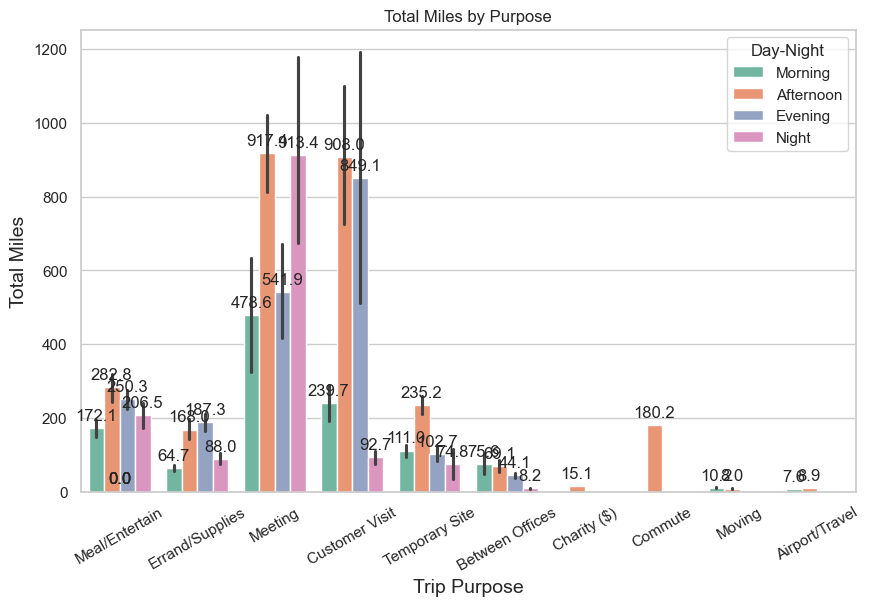

In [42]:
plt.figure(figsize =(10,6))

ax = sns.barplot(data = uber_df , x = 'PURPOSE*' , y = 'MILES*' ,hue = 'Day-Night', estimator = sum , ci= 68 , palette = 'Set2')
for p in ax.patches:
    ax.annotate( f'{p.get_height():.1f}', (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='center', xytext=(0, 9), textcoords='offset points' )
plt.xticks(rotation = 30)
plt.xlabel('Trip Purpose',fontsize = 14)
plt.ylabel('Total Miles',fontsize = 14)
plt.title('Total Miles by Purpose')
plt.show()

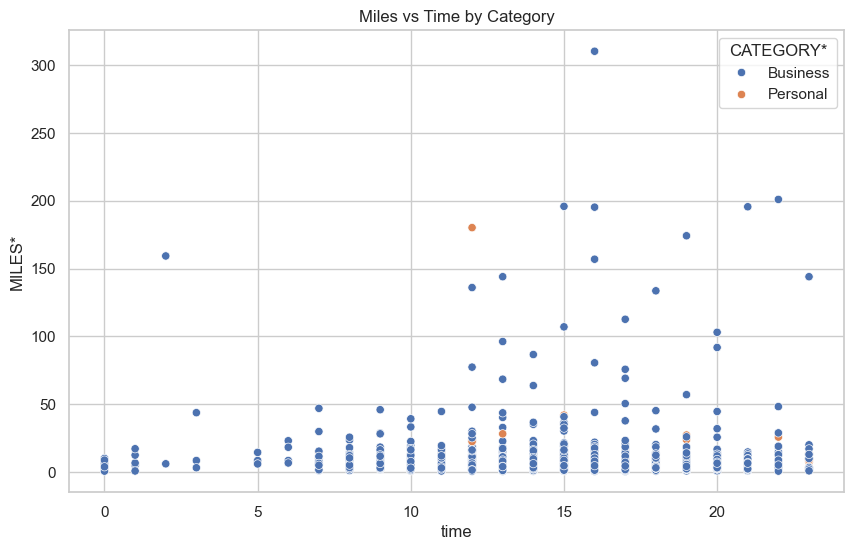

In [43]:
plt.figure(figsize = (10,6))
sns.scatterplot( data = uber_df , x = 'time' , y = 'MILES*' , hue = 'CATEGORY*')
plt.title('Miles vs Time by Category')
plt.show()

In [ ]:
print(uber_df.columns)

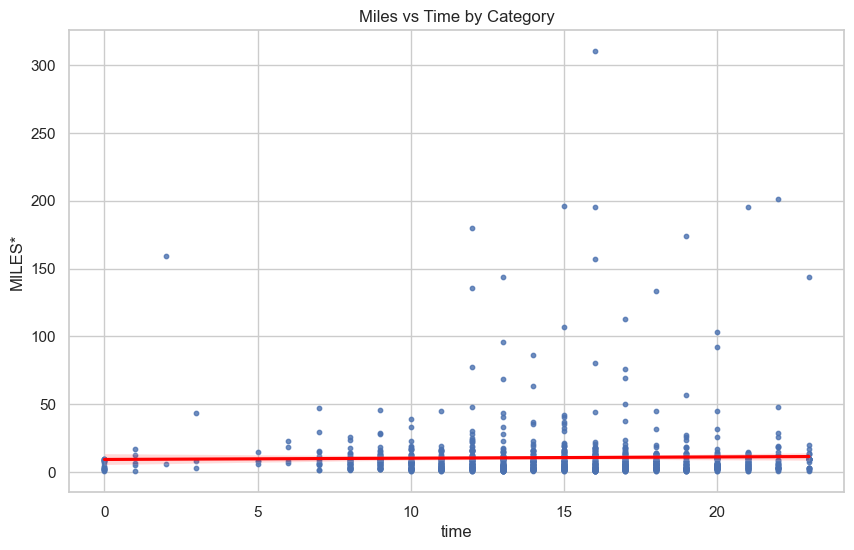

In [44]:
plt.figure(figsize = (10,6))
sns.regplot ( data = uber_df , x = 'time' , y = 'MILES*' ,scatter_kws = {'s' : 10 } , line_kws = {'color' : 'red'})
plt.title('Miles vs Time by Category')
plt.show()

In [ ]:
g = sns.FacetGrid(uber_df , col = 'CATEGORY*' , height = 5 , aspect = 1.5)
g.map(sns.scatterplot, 'time','MILES*')
g.add_legend()
plt.show()

In [ ]:
print(uber_df.columns)

In [ ]:
plt.figure(figsize = (10,6))
sns.scatterplot( data = uber_df , x = 'time' , y = 'MILES*' , hue = 'CATEGORY*',sizes =(20,200))
plt.yscale('log')
plt.title('Miles vs Time by Category (log scale)')
plt.show()

In [ ]:
plt.figure(figsize = (10,6))
sns.stripplot( data = uber_df , x = 'time' , y = 'MILES*' , hue = 'CATEGORY*',jitter = True)

plt.title('Miles vs Time by Category (with jitter)')
plt.show()

In [ ]:
plt.figure(figsize = (10,6))
sns.scatterplot( data = uber_df , x = 'time' , y = 'MILES*' , hue = 'CATEGORY*',alpha = 0.5)

plt.title('Miles vs Time by Category (with transparency)')
plt.show()

In [ ]:
def round(x):
    if x['START*'] == x['STOP*']:
        return 'Yes'
    else:
        return 'No'

uber_df['ROUND_TRIP'] = uber_df.apply(round , axis = 1)
sns.countplot(y = uber_df['ROUND_TRIP'])
plt.show()


In [ ]:
uber_df['MONTH'] = pd.DatetimeIndex(uber_df['START_DATE*']).month
dict = { 1:'Jan', 2:'Feb', 3:'Mar', 4:'Apr', 5:'May', 6:'June', 7:'July', 8:'Aug', 9:'Sep', 10:'Oct', 11:'Nov', 12:'Dec'}

uber_df['MONTH'] = uber_df['MONTH'].map(dict)

plt.figure(figsize = (15,7))
sns.countplot(y = uber_df['MONTH'])
plt.show()

In [ ]:
uber_df['MONTH'] = uber_df['MONTH'].map(dict)

In [ ]:
print(uber_df.columns)

In [ ]:
uber_df.groupby(['MONTH', 'PURPOSE*'])['ROUND_TRIP'].count()

In [54]:

import pandas as pd
import numpy as np

# Convert date columns to datetime
uber_df['START_DATE*'] = pd.to_datetime(
    uber_df['START_DATE*'], errors='coerce'
)
uber_df['END_DATE*'] = pd.to_datetime(
    uber_df['END_DATE*'], errors='coerce'
)

# Add date
uber_df['date'] = uber_df['START_DATE*'].dt.date

# Add weekday
uber_df['WEEKDAY'] = uber_df['START_DATE*'].dt.day_name()

# Add hour of ride
uber_df['time1'] = uber_df['START_DATE*'].dt.hour

# Add round-trip indicator
uber_df['ROUND_TRIP'] = (
    uber_df['START*'].astype(str).str.strip().str.lower()
    == uber_df['STOP*'].astype(str).str.strip().str.lower()
)

# Add ride duration in minutes
uber_df['RIDE_DURATION'] = (
    uber_df['END_DATE*'] - uber_df['START_DATE*']
).dt.total_seconds() / 60

# Add MINUTES column
uber_df['MINUTES'] = uber_df['RIDE_DURATION']

# Add next ride's start time
uber_df['NEXT_RIDE'] = uber_df['START_DATE*'].shift(-1)

# Add time difference between current ride's end
# and the next ride's start, in minutes
uber_df['TIME_DIFF'] = (
    uber_df['NEXT_RIDE'] - uber_df['END_DATE*']
).dt.total_seconds() / 60

# Display all columns
print(uber_df.columns.tolist())
uber_df.head()


['START_DATE*', 'END_DATE*', 'CATEGORY*', 'START*', 'STOP*', 'MILES*', 'PURPOSE*', 'time', 'Day-Night', 'MONTH', 'date', 'WEEKDAY', 'time1', 'ROUND_TRIP', 'RIDE_DURATION', 'MINUTES', 'NEXT_RIDE', 'TIME_DIFF']


,START_DATE*,END_DATE*,CATEGORY*,START*,STOP*,MILES*,PURPOSE*,time,Day-Night,MONTH,date,WEEKDAY,time1,ROUND_TRIP,RIDE_DURATION,MINUTES,NEXT_RIDE,TIME_DIFF
0,2016-01-01 21:11:00,2016-01-01 21:17:00,Business,Fort Pierce,Fort Pierce,5.1,Meal/Entertain,21.0,Night,January,2016-01-01,Friday,21.0,True,6.0,6.0,2016-01-02 01:25:00,248.0
1,2016-01-02 01:25:00,2016-01-02 01:37:00,Business,Fort Pierce,Fort Pierce,5.0,NaN,1.0,Morning,January,2016-01-02,Saturday,1.0,True,12.0,12.0,2016-01-02 20:25:00,1128.0
2,2016-01-02 20:25:00,2016-01-02 20:38:00,Business,Fort Pierce,Fort Pierce,4.8,Errand/Supplies,20.0,Night,January,2016-01-02,Saturday,20.0,True,13.0,13.0,2016-01-05 17:31:00,4133.0
3,2016-01-05 17:31:00,2016-01-05 17:45:00,Business,Fort Pierce,Fort Pierce,4.7,Meeting,17.0,Evening,January,2016-01-05,Tuesday,17.0,True,14.0,14.0,2016-01-06 14:42:00,1257.0
4,2016-01-06 14:42:00,2016-01-06 15:49:00,Business,Fort Pierce,West Palm Beach,63.7,Customer Visit,14.0,Afternoon,January,2016-01-06,Wednesday,14.0,False,67.0,67.0,2016-01-06 17:15:00,86.0


<h3>How Minutes taken To Cover Miles</h3>

In [ ]:
uber_df['MINUTES*'] = uber_df['END_DATE*'] - uber_df['START_DATE*']

In [ ]:
uber_df.head()

In [ ]:
sns.lineplot(data = uber_df, x = uber_df['MINUTES*'], y = uber_df['MILES*'])
plt.show()

In [ ]:
plt.figure(figsize = (15,5))
plt.subplot(1,2,1)
sns.boxplot(data = uber_df , x = uber_df['PURPOSE*'], y = uber_df['MILES*'])
plt.xticks(rotation = 45)

plt.subplot(1,2,2)
sns.boxplot(data = uber_df , x = uber_df['PURPOSE*'], y = uber_df['MINUTES*'])
plt.xticks(rotation = 45)

plt.show()

<h3>For each purpose what is minimum miles travelled, mean miles travelled and what is maximum miles travelled?</h3>

In [ ]:
pd.DataFrame({'Min': uber_df.groupby(['PURPOSE*'])['MILES*'].min(),
              'Mean': uber_df.groupby(['PURPOSE*'])['MILES*'].mean(),
              'Max': uber_df.groupby(['PURPOSE*'])['MILES*'].max()})



<h3>Round Trips For Every Purpose Every Month?</h3>

In [ ]:
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 200)
pd.set_option('display.float_format', '{:.2f}'.format)
pd.set_option('display.precision', 3)
pd.set_option('display.expand_frame_repr', False)
pd.set_option('display.large_repr','info')

data = {f'Column_{i+1}': list(range(500)) for i in range(10)}
df = pd.DataFrame(data)
df









In [ ]:
uber_df.groupby(['MONTH','PURPOSE*'])['ROUND_TRIP'].count()

In [ ]:
import pandas as pd

# Display options
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 60)
pd.set_option('display.max_colwidth', 200)
pd.set_option('display.precision', 3)

# Create data
data = {
    'Floats': [1.23456, 86.34560, 12.65432]
}

# Create DataFrame
df = pd.DataFrame(data)

# Display floating-point numbers with 1 decimal place
pd.options.display.float_format = '{:.1f}'.format

# Display DataFrame
print(df)

In [ ]:
uber_df['START_DATE*'] = pd.to_datetime(uber_df['START_DATE*'], format = 'mixed')

uber_df['WEEKDAY'] = uber_df['START_DATE*'].dt.day_name()

plt.figure(figsize = (10, 6))
sns.countplot(data = uber_df, x = 'WEEKDAY', order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'], palette = 'Set3')

In [ ]:
uber_df['START_DATE*'] = pd.to_datetime(uber_df['START_DATE*'], format = 'mixed', errors = 'coerce')

uber_df['WEEKDAY'] = uber_df['START_DATE*'].dt.day_name()

plt.figure(figsize = (10, 6))
sns.countplot(data = uber_df, x = 'WEEKDAY', order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'], palette = 'Set3')
plt.title('Number of Rides by Day of the Week')
plt.xlabel('Weekday')
plt.ylabel('Count')
plt.show()

In [ ]:
print(uber_df.columns)

In [ ]:
uber_df['ROUND_TRIP'] = uber_df['START*'] == uber_df['END_D4z*']

round_trip_counts = uber_df['ROUND_TRIP'].value_counts()

plt.figure(figsize = (10, 6))
round_trip_counts.plot(kind = 'pie', autopct = '%1.1f%%', startangle = 90, colors = ['#ff9999', '#66b3ff'])
plt.title('Proportion of Round Trips')
plt.ylabel('')
plt.show()

CATEGORY*
Business    11487.0
Personal      717.7
Name: MILES*, dtype: float64


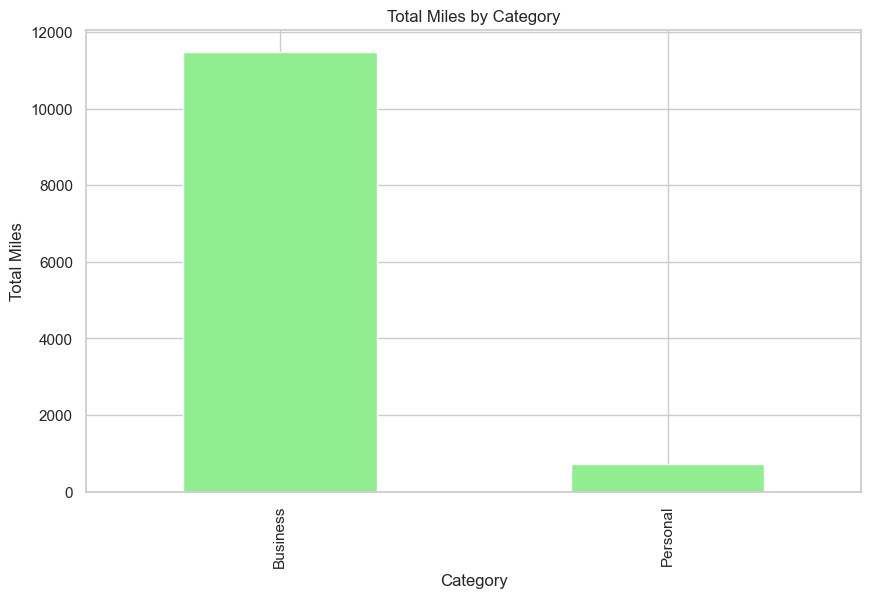

In [46]:
total_miles_by_category = uber_df.groupby('CATEGORY*')['MILES*'].sum()
print(total_miles_by_category)

plt.figure(figsize = (10, 6))
total_miles_by_category.plot(kind = 'bar', color = 'lightgreen')
plt.title('Total Miles by Category')
plt.xlabel('Category')
plt.ylabel('Total Miles')
plt.show()

C:\Users\abdul jabbar\AppData\Local\Temp\ipykernel_16492\2290608128.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data = uber_df, x = 'MONTH', palette = 'Set1')


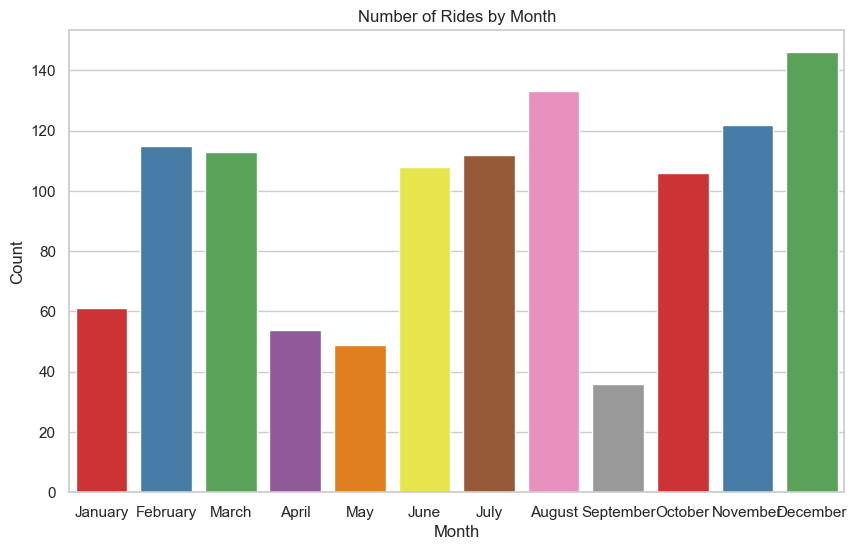

In [48]:
uber_df['START_DATE*'] = pd.to_datetime(uber_df['START_DATE*'], format = 'mixed', errors = 'coerce')

uber_df['MONTH'] = uber_df['START_DATE*'].dt.month_name()

plt.figure(figsize = (10, 6))

sns.countplot(data = uber_df, x = 'MONTH', palette = 'Set1')

plt.title('Number of Rides by Month')

plt.xlabel('Month')

plt.ylabel('Count')

plt.show()

START*
Cary                201
Unknown Location    148
Morrisville          85
Whitebridge          68
Islamabad            57
Durham               37
Lahore               36
Raleigh              28
Kar?chi              27
Westpark Place       17
Name: count, dtype: int64


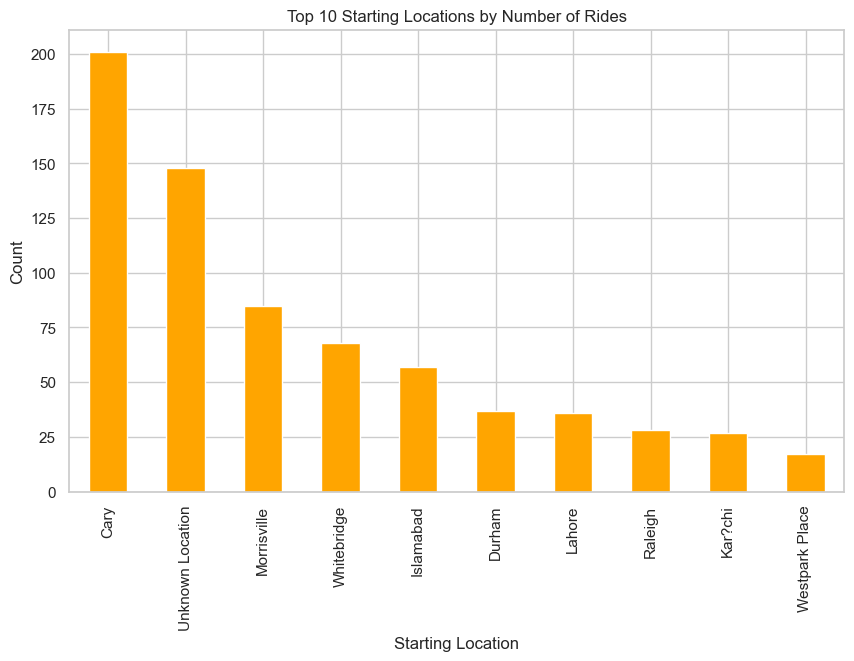

In [56]:
top_start_locations = uber_df['START*'].value_counts().head(10)

print(top_start_locations)

plt.figure(figsize = (10, 6))

top_start_locations.plot(kind = 'bar', color = 'orange')

plt.title('Top 10 Starting Locations by Number of Rides')

plt.xlabel('Starting Location')

plt.ylabel('Count')

plt.show()

START*
Cary                201
Unknown Location    148
Morrisville          85
Whitebridge          68
Islamabad            57
Durham               37
Lahore               36
Raleigh              28
Kar?chi              27
Westpark Place       17
Name: count, dtype: int64


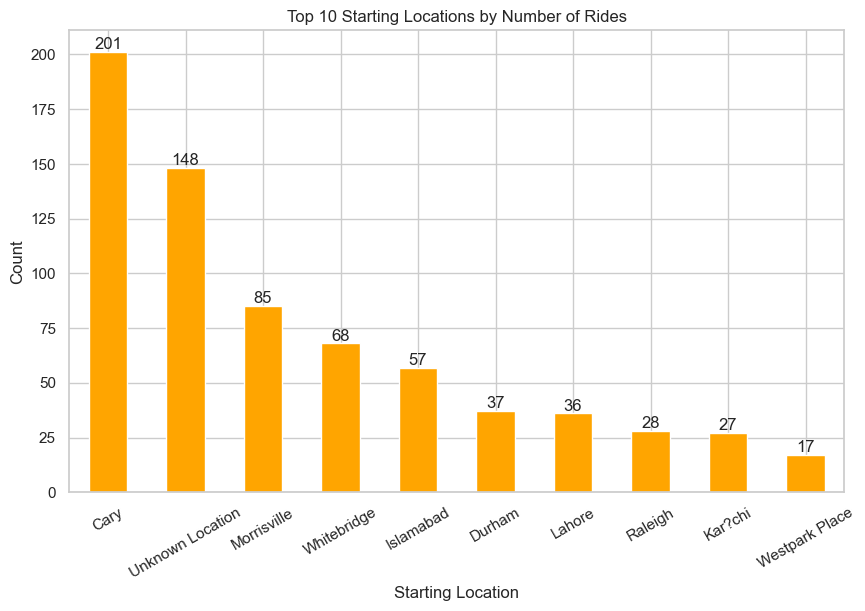

In [50]:
top_start_locations = uber_df['START*'].value_counts().head(10)

print(top_start_locations)

plt.figure(figsize = (10, 6))

ax = top_start_locations.plot(kind = 'bar', color = 'orange')

plt.title('Top 10 Starting Locations by Number of Rides')

plt.xlabel('Starting Location')

plt.ylabel('Count')

plt.xticks(rotation = 30)

for p in ax.patches:
    ax.annotate(f'{p.get_height()}', (p.get_x() + p.get_width() / 2, p.get_height()), ha = 'center', va = 'bottom')

plt.show()

C:\Users\abdul jabbar\AppData\Local\Temp\ipykernel_16492\189172848.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data = uber_df, x = 'time', palette = 'viridis')


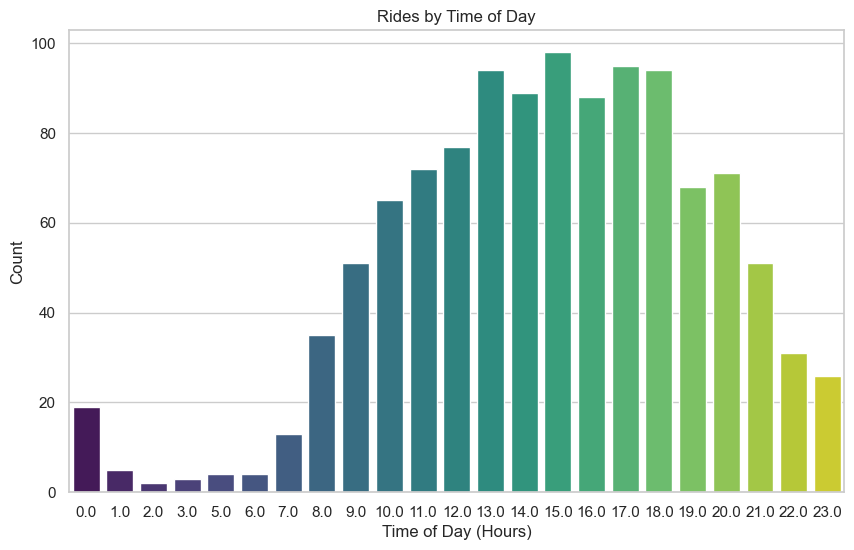

In [52]:
plt.figure(figsize = (10, 6))

sns.countplot(data = uber_df, x = 'time', palette = 'viridis')

plt.title('Rides by Time of Day')

plt.xlabel('Time of Day (Hours)')

plt.ylabel('Count')

for p in ax.patches:
    ax.annotate(f'{p.get_height()}', (p.get_x() + p.get_width() / 2, p.get_height()), ha = 'center', va = 'bottom')

plt.show()

In [55]:
uber_df.columns

Index(['START_DATE*', 'END_DATE*', 'CATEGORY*', 'START*', 'STOP*', 'MILES*',
       'PURPOSE*', 'time', 'Day-Night', 'MONTH', 'date', 'WEEKDAY', 'time1',
       'ROUND_TRIP', 'RIDE_DURATION', 'MINUTES', 'NEXT_RIDE', 'TIME_DIFF'],
      dtype='object')

In [57]:

# Convert start and end dates to datetime
uber_df['START_DATE*'] = pd.to_datetime(
    uber_df['START_DATE*'], errors='coerce'
)
uber_df['END_DATE*'] = pd.to_datetime(
    uber_df['END_DATE*'], errors='coerce'
)

# Calculate ride duration in minutes
uber_df['ride_duration'] = (
    uber_df['END_DATE*'] - uber_df['START_DATE*']
).dt.total_seconds() / 60

# Find minimum and maximum duration by category
duration_by_category = (
    uber_df.groupby('CATEGORY*')['ride_duration']
    .agg(['min', 'max'])
)

duration_by_category


,min,max
CATEGORY*,,
Business,0.0,178.0
Personal,4.0,16.0


In [60]:

# Convert miles to numeric values
uber_df['MILES*'] = pd.to_numeric(
    uber_df['MILES*'], errors='coerce'
)

# Calculate total miles by month
miles_by_month = uber_df.groupby('MONTH')['MILES*'].sum()

# Find the month with the highest total miles
most_miles_month = miles_by_month.idxmax()

# Display results
print("Month with the most miles:", most_miles_month)
print("\nTotal miles by month:")
print(miles_by_month)


Month with the most miles: October

Total miles by month:
MONTH
April        1113.0
August       1335.5
December      981.3
February      908.2
January       512.9
July         1224.6
June          842.8
March        1693.9
May           363.8
November      816.9
October      1810.0
September     601.8
Name: MILES*, dtype: float64


In [61]:

import pandas as pd

# Convert start date to datetime
uber_df['START_DATE*'] = pd.to_datetime(
    uber_df['START_DATE*'], errors='coerce'
)

# Extract weekday and calendar date
uber_df['WEEKDAY'] = uber_df['START_DATE*'].dt.day_name()
uber_df['DATE'] = uber_df['START_DATE*'].dt.date

# Count rides for each weekday
rides_by_weekday = uber_df.groupby('WEEKDAY').size()

# Count distinct dates recorded for each weekday
days_by_weekday = uber_df.groupby('WEEKDAY')['DATE'].nunique()

# Calculate average rides per day
average_rides_by_weekday = (
    rides_by_weekday / days_by_weekday
).reindex([
    'Monday', 'Tuesday', 'Wednesday', 'Thursday',
    'Friday', 'Saturday', 'Sunday'
])

print("Average rides per day for each weekday:")
print(average_rides_by_weekday.round(2))


Average rides per day for each weekday:
WEEKDAY
Monday       4.46
Tuesday      3.74
Wednesday    3.68
Thursday     3.67
Friday       4.29
Saturday     3.66
Sunday       4.00
dtype: float64


In [64]:
avg_miles_day_night = uber_df.groupby('Day-Night')['MILES*'].mean()

avg_miles_day_night


C:\Users\abdul jabbar\AppData\Local\Temp\ipykernel_16492\2816325382.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  avg_miles_day_night = uber_df.groupby('Day-Night')['MILES*'].mean()


Day-Night
Morning       9.392040
Afternoon    10.496279
Evening      10.770435
Night        11.663128
Name: MILES*, dtype: float64

In [66]:
same_location_rides = uber_df[uber_df['START*'] == uber_df['STOP*']]

num_same_location_rides = same_location_rides.shape[0]

avg_miles_same_location = same_location_rides['MILES*'].mean()

num_same_location_rides, avg_miles_same_location


(288, np.float64(7.742361111111112))

In [69]:
avg_duration_by_purpose = uber_df.groupby('PURPOSE*')['RIDE_DURATION'].mean()

print(avg_duration_by_purpose)


PURPOSE*
Airport/Travel           NaN
Between Offices    25.666667
Charity ($)              NaN
Commute                  NaN
Customer Visit     31.608696
Errand/Supplies    12.404255
Meal/Entertain     14.437500
Meeting            25.740741
Moving                   NaN
Temporary Site     18.714286
Name: RIDE_DURATION, dtype: float64


In [71]:
uber_df = uber_df.sort_values('START_DATE*')

uber_df['NEXT_RIDE'] = uber_df.groupby('DATE')['START_DATE*'].shift(-1)

uber_df['TIME_DIFF'] = (uber_df['NEXT_RIDE'] - uber_df['START_DATE*']).dt.total_seconds() / 60

avg_time_diff = uber_df.groupby('DATE')['TIME_DIFF'].mean().dropna()

avg_time_diff




DATE
2016-01-02    1140.000000
2016-01-06      84.000000
2016-01-10     166.750000
2016-01-11     111.666667
2016-01-12      41.800000
                 ...     
2016-12-27     147.400000
2016-12-28     141.666667
2016-12-29     112.083333
2016-12-30     192.750000
2016-12-31     315.250000
Name: TIME_DIFF, Length: 259, dtype: float64